# AutoPilotRL — The learning video: from zero to parked

A video that shows **learning itself**: the same AI, at different moments of its training, tries to park in the **same spot**.
- At first it does nonsense: it wanders around, hits the walls, stops in the wrong place.
- Attempt after attempt it gets closer.
- In the end it parks.

## How it is made
1. We train SAC + HER **from zero**, exactly as in v6.
2. During training we take **snapshots** of the actor: a copy of its weights at chosen moments (before training, after 2,000 steps, after 4,000, …).
3. After training, every snapshot drives the **same scenario**, and we film each attempt. Every snapshot drives **without exploration noise** ($a = \tanh(\mu_\theta(s))$): the clip shows the best the AI could do at that moment.
4. The clips are joined into one video, with:
   - on the left, the simulator: our car and the target spot;
   - on the right, the **learning curve** (success rate during training), lit up to the current moment;
   - on top, how much practice the AI has had so far;
   - at the end of each attempt, the result: **PARKED**, **CRASH** or **TIME UP**.

The video opens with a title card and closes with a summary card.

## Running it
- Training takes about **6–8 minutes** and making the video about **2–3 minutes**.
- The snapshots are saved in `results/learning_snapshots.pt`. If the file exists, the training is skipped, so you can remake the video (another scenario, another speed) in a couple of minutes.
- For an MP4 install `pip install imageio imageio-ffmpeg`; otherwise you get a GIF.

Run everything with **Run All**.

In [1]:
# --- SETTINGS (edit here) ---

# The scenario every snapshot tries (a test seed: never used in training).
SCENARIO_SEED = 1000

# True: every attempt on the same scenario. False: a different scenario for every attempt.
SAME_SCENARIO = True

# Environment steps of training.
TRAIN_STEPS = 40_000

# When to take a snapshot of the actor (environment steps).
SNAPSHOT_STEPS = [0, 2_000, 4_000, 6_000, 8_000, 10_000, 13_000, 16_000, 20_000, 25_000, 30_000, 40_000]

# Video speed: 3 = three times real time.
SPEED = 3

# Longest an attempt may last in the video (seconds): longer attempts are fast-forwarded.
MAX_ATTEMPT_SECONDS = 5

# "mp4" or "gif".
VIDEO_FORMAT = "mp4"

# Skip training if the snapshots file already exists.
REUSE_SNAPSHOTS = True

In [2]:
# --- LIBRARIES ---

# Gymnasium: the standard interface for RL environments.
import gymnasium as gym

# Registers the highway-env environments.
import highway_env

# Numerical computing.
import numpy as np

# PyTorch: tensors and neural networks.
import torch

# Neural network layers.
import torch.nn as nn

# Loss functions.
import torch.nn.functional as F

# Probability distributions.
from torch.distributions import Normal

# Plotting in the notebook.
import matplotlib.pyplot as plt

# A figure that is drawn off-screen, for the video frames.
from matplotlib.figure import Figure

# Its off-screen canvas.
from matplotlib.backends.backend_agg import FigureCanvasAgg

# Images for GIFs.
from PIL import Image as PILImage

# Show images and videos in the notebook.
from IPython.display import Image, Video, display

# Independent copies of the weights.
import copy

# File and folder paths.
from pathlib import Path

# Measure time.
import time

# Folder for the videos.
VIDEO_DIR = Path("videos")

# Create it if needed.
VIDEO_DIR.mkdir(exist_ok=True)

# Folder for the results.
RESULTS_DIR = Path("results")

# Create it if needed.
RESULTS_DIR.mkdir(exist_ok=True)

# Where the snapshots are stored.
SNAPSHOT_FILE = RESULTS_DIR / "learning_snapshots.pt"

# The parking environment.
ENV_NAME = "parking-v0"

# Small networks: the CPU is the fastest choice.
device = torch.device("cpu")

# Reproducibility for PyTorch.
torch.manual_seed(0)

# Versions.
print(f"torch {torch.__version__} | gymnasium {gym.__version__}")

torch 2.14.1 | gymnasium 1.4.0


## Step 1 — Environment and SAC + HER (the same as v6)

The environment, the networks and the replay buffer are **identical to v6**; see v6 for every formula. As a reminder:
- **Observation:** our car and the target spot, as $(x, y, v_x, v_y, \cos\psi, \sin\psi)$.
- **Action:** acceleration and steering, both in $[-1, 1]$.
- **Reward:** $r = -\big(\sum_i w_i |s_i - g_i|\big)^{1/2} - 5 \cdot \text{crashed}$.
- **Success** when that distance is below 0.12; each episode lasts at most 20 s.
- **SAC:**
  - the actor is a squashed Gaussian, $a = \tanh(\mu_\theta(s) + \sigma_\theta(s)\,\varepsilon)$;
  - two critics, and the target takes their minimum;
  - the temperature α is tuned automatically.
- **HER:** 80% of the sampled transitions get as goal a place the car really reached later in the same episode.

In [3]:
# --- ENVIRONMENTS ---

# Episodes of 20 seconds (100 decisions), as in v6.
ENV_CONFIG = {"duration": 20}

# Training environment.
env = gym.make(ENV_NAME, config=ENV_CONFIG)

# Filming environment.
env_render = gym.make(ENV_NAME, render_mode="rgb_array", config=ENV_CONFIG)

# Weights of the reward.
REWARD_WEIGHTS = np.array(env.unwrapped.config["reward_weights"])

# Success threshold.
SUCCESS_THRESHOLD = env.unwrapped.config["success_goal_reward"]

# Penalty for a crash.
COLLISION_REWARD = env.unwrapped.config["collision_reward"]

# Decisions per second.
POLICY_HZ = env.unwrapped.config["policy_frequency"]

# Size of each vector of the observation.
OBS_DIM = env.observation_space["observation"].shape[0]

# Number of actions.
ACT_DIM = env.action_space.shape[0]


# The goal part of the reward, for one goal or a batch of goals.
def goal_reward(achieved, desired):
    """-(sum_i w_i |achieved_i - desired_i|) ** 0.5, along the last axis."""

    # Weighted L1 distance, square root, minus sign.
    return -np.power(np.abs(achieved - desired) @ REWARD_WEIGHTS, 0.5)


# Report.
print(f"{ENV_NAME}: action space {env.action_space}, episodes of {ENV_CONFIG['duration']} s at {POLICY_HZ} Hz")

parking-v0: action space Box(-1.0, 1.0, (2,), float32), episodes of 20 s at 5 Hz


In [4]:
# --- SAC NETWORKS ---

# Width of the hidden layers.
HIDDEN = 256

# Network input: observation (6) + desired goal (6).
IN_DIM = 2 * OBS_DIM

# Positions x, y are multiplied by 10 (they arrive divided by 100); the other features stay as they are.
INPUT_SCALE = np.array([10, 10, 1, 1, 1, 1] * 2, dtype=np.float32)


# Build the network input from observations and goals (single vectors or batches).
def make_input(observation, goal):
    """Concatenate along the last axis and rescale -> float32 tensor."""

    # Concatenate.
    x = np.concatenate([observation, goal], axis=-1) * INPUT_SCALE

    # As a tensor.
    return torch.as_tensor(x, dtype=torch.float32)


# Multilayer perceptron with two hidden ReLU layers.
def mlp(in_dim, out_dim, hidden=HIDDEN):
    """in -> hidden -> hidden -> out."""

    # The layers in sequence.
    return nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, out_dim))


# Actor: input -> tanh-squashed Gaussian action.
class SquashedGaussianActor(nn.Module):
    """Mean and log-std depend on the state; a = tanh(mean + std * eps)."""

    # Build the layers.
    def __init__(self, in_dim=IN_DIM, act_dim=ACT_DIM, hidden=HIDDEN):

        # Initialise nn.Module.
        super().__init__()

        # Shared body.
        self.body = nn.Sequential(nn.Linear(in_dim, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU())

        # Mean of u.
        self.mean_head = nn.Linear(hidden, act_dim)

        # Log standard deviation of u.
        self.log_std_head = nn.Linear(hidden, act_dim)

    # Sample an action (or the deterministic one) and its log-probability.
    def forward(self, x, deterministic=False):
        """x: (B, IN_DIM) -> actions (B, ACT_DIM), log_prob (B,) or None."""

        # Hidden features.
        h = self.body(x)

        # Mean.
        mean = self.mean_head(h)

        # Log-std, kept in a safe range.
        log_std = self.log_std_head(h).clamp(-20, 2)

        # Deterministic action for evaluation.
        if deterministic:

            # Squash the mean.
            return torch.tanh(mean), None

        # Gaussian over u.
        dist = Normal(mean, log_std.exp())

        # Reparameterised sample: mean + std * eps (gradients flow through it).
        u = dist.rsample()

        # Squash into [-1, 1].
        action = torch.tanh(u)

        # log N(u) minus the tanh correction, summed over the action dimensions.
        log_prob = dist.log_prob(u).sum(dim=1) - torch.log(1 - action.pow(2) + 1e-6).sum(dim=1)

        # Action and its log-probability.
        return action, log_prob


# Critic: (input, action) -> Q-value.
class QNet(nn.Module):
    """Q(s, g, a)."""

    # Build the layers.
    def __init__(self, in_dim=IN_DIM, act_dim=ACT_DIM):

        # Initialise nn.Module.
        super().__init__()

        # One MLP on the concatenation of state-goal and action.
        self.net = mlp(in_dim + act_dim, 1)

    # Forward pass.
    def forward(self, x, action):
        """-> (B,)."""

        # Concatenate and evaluate.
        return self.net(torch.cat([x, action], dim=1)).squeeze(-1)


# Discount factor.
GAMMA = 0.95

# Learning rate.
LR = 1e-3

# Polyak coefficient of the target networks.
TAU = 0.05

# Target entropy: minus the number of action dimensions.
TARGET_ENTROPY = -float(ACT_DIM)


# Everything SAC needs: actor, twin critics, their targets, temperature, optimisers.
class SACAgent:
    """One SAC learner."""

    # Create the networks and optimisers.
    def __init__(self):

        # Actor.
        self.actor = SquashedGaussianActor()

        # Twin critics.
        self.q1, self.q2 = QNet(), QNet()

        # Their target copies.
        self.q1_target, self.q2_target = copy.deepcopy(self.q1), copy.deepcopy(self.q2)

        # Log of the temperature (alpha = 1 at the start).
        self.log_alpha = torch.zeros(1, requires_grad=True)

        # Actor optimiser.
        self.actor_opt = torch.optim.Adam(self.actor.parameters(), lr=LR)

        # One optimiser for both critics.
        self.critic_opt = torch.optim.Adam(list(self.q1.parameters()) + list(self.q2.parameters()), lr=LR)

        # Temperature optimiser.
        self.alpha_opt = torch.optim.Adam([self.log_alpha], lr=LR)

    # Current temperature.
    @property
    def alpha(self):
        """exp(log_alpha) as a plain number."""

        # As a float.
        return self.log_alpha.exp().item()

    # Choose an action for one observation.
    @torch.no_grad()
    def act(self, observation, goal, deterministic=False):
        """-> NumPy array (ACT_DIM,)."""

        # Action for a batch of one.
        action, _ = self.actor(make_input(observation, goal).unsqueeze(0), deterministic=deterministic)

        # As NumPy.
        return action[0].numpy()

    # One SAC update on a batch.
    def update(self, x, action, reward, x_next, done):
        """All tensors with batch dimension first. Returns the critic loss."""

        # Current temperature, as a constant.
        alpha = self.log_alpha.exp().detach()

        # --- Critics ---
        with torch.no_grad():

            # Next action and its log-probability, from the current policy.
            next_action, next_log_prob = self.actor(x_next)

            # Pessimistic target value, with the entropy bonus.
            next_q = torch.min(self.q1_target(x_next, next_action), self.q2_target(x_next, next_action)) - alpha * next_log_prob

            # Soft Bellman target (no bootstrap after a terminal transition).
            y = reward + GAMMA * (1.0 - done) * next_q

        # Both critics regress towards the same target.
        critic_loss = F.mse_loss(self.q1(x, action), y) + F.mse_loss(self.q2(x, action), y)

        # Clear the old gradients.
        self.critic_opt.zero_grad()

        # Backpropagation.
        critic_loss.backward()

        # Update the critics.
        self.critic_opt.step()

        # --- Actor ---
        # Fresh reparameterised actions for the same states.
        new_action, log_prob = self.actor(x)

        # Value of those actions according to the (pessimistic) critics.
        q_new = torch.min(self.q1(x, new_action), self.q2(x, new_action))

        # High Q, but stay random.
        actor_loss = (alpha * log_prob - q_new).mean()

        # Clear the old gradients.
        self.actor_opt.zero_grad()

        # Backpropagation (this also fills gradients in the critics: they are cleared before their next step).
        actor_loss.backward()

        # Update the actor.
        self.actor_opt.step()

        # --- Temperature ---
        alpha_loss = -(self.log_alpha * (log_prob.detach() + TARGET_ENTROPY)).mean()

        # Clear the old gradient.
        self.alpha_opt.zero_grad()

        # Backpropagation.
        alpha_loss.backward()

        # Update alpha.
        self.alpha_opt.step()

        # --- Targets: Polyak averaging ---
        with torch.no_grad():

            # Both critic pairs.
            for net, target in [(self.q1, self.q1_target), (self.q2, self.q2_target)]:

                # Every parameter.
                for p, p_target in zip(net.parameters(), target.parameters()):

                    # Move the target a little towards the online network.
                    p_target.mul_(1 - TAU).add_(TAU * p)

        # For the learning curves.
        return critic_loss.item()

In [5]:
# --- REPLAY BUFFER WITH HER ---

# Probability of replacing the goal of a sampled transition with a future achieved goal.
HER_PROB = 0.8


# Stores whole episodes and relabels goals at sampling time.
class HERReplayBuffer:
    """Flat arrays of transitions + the index of the last transition of each one's episode."""

    # Allocate the arrays.
    def __init__(self, capacity):

        # Observation before the step.
        self.obs = np.zeros((capacity, OBS_DIM), dtype=np.float32)

        # Desired goal of the episode.
        self.goal = np.zeros((capacity, OBS_DIM), dtype=np.float32)

        # Action taken.
        self.action = np.zeros((capacity, ACT_DIM), dtype=np.float32)

        # Observation after the step.
        self.next_obs = np.zeros((capacity, OBS_DIM), dtype=np.float32)

        # Achieved goal after the step (the candidates for relabelling).
        self.achieved_next = np.zeros((capacity, OBS_DIM), dtype=np.float32)

        # Crashed at this step.
        self.crashed = np.zeros(capacity, dtype=np.float32)

        # Index of the last transition of the episode.
        self.ep_end = np.zeros(capacity, dtype=np.int64)

        # Number of stored transitions.
        self.size = 0

        # Its own random generator.
        self.rng = np.random.default_rng(0)

    # Store a finished episode.
    def add_episode(self, transitions):
        """transitions: list of (obs, goal, action, next_obs, achieved_next, crashed)."""

        # Where the episode starts in the arrays.
        start = self.size

        # Where it ends.
        end = start + len(transitions) - 1

        # Copy every transition.
        for i, (o, g, a, o2, ag2, c) in enumerate(transitions):

            # Position in the arrays.
            k = start + i

            # Observation.
            self.obs[k] = o

            # Goal.
            self.goal[k] = g

            # Action.
            self.action[k] = a

            # Next observation.
            self.next_obs[k] = o2

            # Achieved goal after the step.
            self.achieved_next[k] = ag2

            # Crash flag.
            self.crashed[k] = c

            # Last index of this episode.
            self.ep_end[k] = end

        # New size.
        self.size = end + 1

    # Sample a batch, relabelling goals with probability her_prob.
    def sample(self, batch_size, her_prob):
        """Returns tensors (x, action, reward, x_next, done)."""

        # Random transitions.
        idx = self.rng.integers(0, self.size, size=batch_size)

        # Their original goals (a copy: we are going to change some of them).
        goals = self.goal[idx].copy()

        # Which ones get a hindsight goal.
        relabel = self.rng.random(batch_size) < her_prob

        # A future step of the same episode for every transition (from t to the end, inclusive).
        future = self.rng.integers(idx, self.ep_end[idx] + 1)

        # Replace the goal with what the car achieved at that future step.
        goals[relabel] = self.achieved_next[future[relabel]]

        # Goal part of the reward, recomputed for the (possibly new) goals.
        goal_r = goal_reward(self.achieved_next[idx], goals)

        # Full reward, with the crash penalty.
        reward = goal_r + COLLISION_REWARD * self.crashed[idx]

        # Terminal: crash, or success for this goal.
        done = np.maximum(self.crashed[idx], (goal_r > -SUCCESS_THRESHOLD).astype(np.float32))

        # Tensors for the networks.
        return (make_input(self.obs[idx], goals), torch.as_tensor(self.action[idx]),
                torch.as_tensor(reward, dtype=torch.float32), make_input(self.next_obs[idx], goals),
                torch.as_tensor(done, dtype=torch.float32))

## Step 2 — Training with snapshots

The training loop of v6 (1,000 random warm-up steps, then one SAC update per step), with two changes:
- **No validation:** we do not choose a "best" model. We want to see the whole story, including any step backwards.
- **Snapshots:** when the step counter reaches a value in `SNAPSHOT_STEPS`, we store a copy of the actor's weights, together with the number of attempts (episodes) played so far.

A snapshot is cheap: the actor has about 70,000 numbers.

We also store the result of every training episode (parked or not) for the learning curve shown in the video. Snapshots and curve go to `results/learning_snapshots.pt`.

In [6]:
# --- TRAINING WITH SNAPSHOTS ---

# Random actions at the start.
WARMUP = 1_000

# Batch size.
BATCH_SIZE = 256


# Train SAC + HER from zero, taking snapshots of the actor.
def train_with_snapshots(total_steps=TRAIN_STEPS, snapshot_steps=SNAPSHOT_STEPS):
    """Return (snapshots, log). snapshots: {step: {"weights": state_dict, "episodes": int}}."""

    # Same starting weights every run.
    torch.manual_seed(0)

    # The learner.
    agent = SACAgent()

    # Buffer for every step.
    buffer = HERReplayBuffer(total_steps + 200)

    # Random generator for the warm-up.
    warmup_rng = np.random.default_rng(0)

    # Result of every training episode, and the step at which it ended.
    log = {"episode_steps": [], "success": []}

    # The snapshots.
    snapshots = {}

    # Snapshot steps still to take, in order.
    pending = sorted(snapshot_steps)

    # Steps so far.
    steps = 0

    # Training scenarios.
    seed = 10_000

    # Clock.
    start = time.time()

    # Until the budget is used.
    while steps < total_steps:

        # New training scenario.
        obs, info = env.reset(seed=seed)

        # Next one.
        seed += 1

        # Transitions of this episode.
        episode = []

        # Until the end.
        done = False

        # Play.
        while not done:

            # Time for a snapshot?
            while pending and steps >= pending[0]:

                # Copy of the actor's weights and the number of attempts so far.
                snapshots[pending.pop(0)] = {"weights": copy.deepcopy(agent.actor.state_dict()), "episodes": len(log["success"])}

            # Warm-up: random actions.
            if steps < WARMUP:

                # Uniform.
                action = warmup_rng.uniform(-1, 1, size=ACT_DIM).astype(np.float32)

            # Afterwards: the actor, with exploration.
            else:

                # Stochastic action.
                action = agent.act(obs["observation"], obs["desired_goal"])

            # One step.
            next_obs, reward, terminated, truncated, info = env.step(action)

            # Keep the transition.
            episode.append((obs["observation"], obs["desired_goal"], action, next_obs["observation"],
                            next_obs["achieved_goal"], float(env.unwrapped.vehicle.crashed)))

            # Move on.
            obs = next_obs

            # Count.
            steps += 1

            # End?
            done = terminated or truncated

            # One SAC update.
            if steps >= WARMUP and buffer.size >= BATCH_SIZE:

                # Learn from a relabelled batch.
                agent.update(*buffer.sample(BATCH_SIZE, HER_PROB))

            # Progress every 5,000 steps.
            if steps % 5000 == 0:

                # Recent success rate.
                print(f"step {steps:6d} | episodes {len(log['success']):4d} | "
                      f"success (last 50) {np.mean(log['success'][-50:]) if log['success'] else 0:4.0%} | {time.time() - start:.0f}s")

        # Store the finished episode.
        buffer.add_episode(episode)

        # Step at which it ended.
        log["episode_steps"].append(int(steps))

        # Parked or not.
        log["success"].append(float(info["is_success"]))

    # Snapshots not yet taken (at or after the last step): take them now.
    for step in pending:

        # The final actor.
        snapshots[step] = {"weights": copy.deepcopy(agent.actor.state_dict()), "episodes": len(log["success"])}

    # Done.
    return snapshots, log


# Reuse the stored snapshots if allowed and available.
if REUSE_SNAPSHOTS and SNAPSHOT_FILE.exists():

    # Load them (our own file: it also contains plain Python lists).
    stored = torch.load(SNAPSHOT_FILE, weights_only=False)

    # Unpack.
    snapshots, log = stored["snapshots"], stored["log"]

    # Report.
    print(f"Loaded {len(snapshots)} snapshots from {SNAPSHOT_FILE} (set REUSE_SNAPSHOTS = False to train again)")

# Otherwise train.
else:

    # Train from zero.
    snapshots, log = train_with_snapshots()

    # Save for next time.
    torch.save({"snapshots": snapshots, "log": log}, SNAPSHOT_FILE)

    # Report.
    print(f"Saved {len(snapshots)} snapshots to {SNAPSHOT_FILE}")

Loaded 12 snapshots from results/learning_snapshots.pt (set REUSE_SNAPSHOTS = False to train again)


## Step 3 — The learning curve

The curve that appears in the video: the **success rate of the last 30 training attempts**, against the environment steps. The vertical lines are the snapshots, the moments the video will show.

These attempts are made **with exploration** (random noise in the actions), so the curve is a little below what the deterministic snapshots achieve.

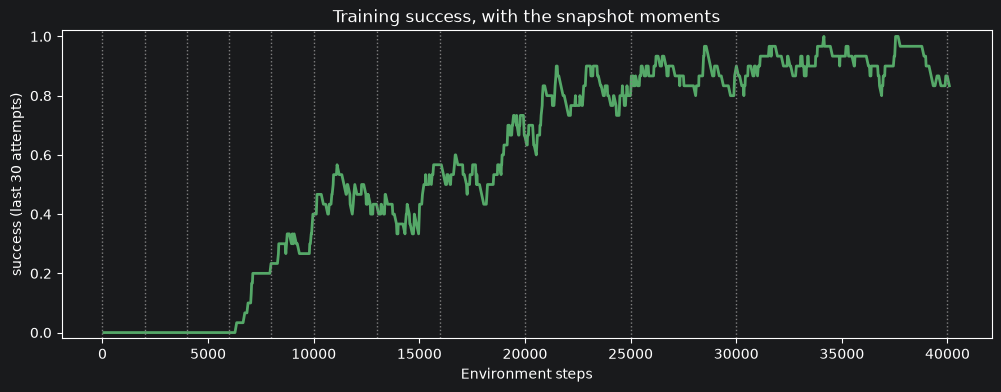

In [7]:
# --- LEARNING CURVE ---

# Window of the moving average.
WINDOW = 30

# Steps at which the episodes ended.
episode_steps = np.array(log["episode_steps"])

# Moving average of the success (the first WINDOW - 1 points use fewer episodes).
success_curve = np.array([np.mean(log["success"][max(0, i - WINDOW + 1):i + 1]) for i in range(len(log["success"]))])

# One panel.
fig, ax = plt.subplots(figsize=(12, 4))

# The curve.
ax.plot(episode_steps, success_curve, color="#55A868", linewidth=2)

# The snapshots.
for step in snapshots:

    # Thin vertical line.
    ax.axvline(step, color="gray", linestyle=":", linewidth=1)

# Labels.
ax.set_xlabel("Environment steps")

# y label.
ax.set_ylabel(f"success (last {WINDOW} attempts)")

# Range.
ax.set_ylim(-0.02, 1.02)

# Title.
ax.set_title("Training success, with the snapshot moments")

# Show.
plt.show()

## Step 4 — Filming each snapshot

For each snapshot:
1. rebuild an actor and load the snapshot's weights;
2. play the scenario (the same for all, or a different one if `SAME_SCENARIO = False`), deterministically;
3. keep one simulator picture per decision.

Each video frame is drawn off-screen with matplotlib, at 1280 × 720 pixels:

```
┌──────────────────────────────────────────────────────────────┐
│        Attempt 5 of 12 — after 8,000 steps (95 episodes)       │
├───────────────────────────────────┬──────────────────────────┤
│                                   │  success during training │
│   simulator: our car + the spot   │   ____/‾‾‾‾  (lit up to  │
│                                   │  /            this point)│
│   [ PARKED / CRASH / TIME UP ]    │                          │
└───────────────────────────────────┴──────────────────────────┘
```

At the end of each attempt the result is shown for one second, near the top so the car stays visible. An attempt longer than `MAX_ATTEMPT_SECONDS` of video (typically one that wanders until the time is up) is **fast-forwarded**: evenly spaced pictures are kept, and the subtitle shows the speed-up.

There is one frame per decision (5 per second of simulation). With `SPEED = 3` the video plays at 15 frames per second, three times real time.

In [8]:
# --- FILMING ---

# Frames per second of the video.
FPS = POLICY_HZ * SPEED

# Frame size: 12.8 x 7.2 inches at 100 dpi = 1280 x 720 pixels.
FIG_SIZE, DPI = (12.8, 7.2), 100

# Background colour.
BG = "#16181c"

# Colour of each result.
RESULT_COLOURS = {"PARKED": "#55A868", "CRASH": "#C44E52", "TIME UP": "#DD8452"}


# A deterministic driver from a snapshot.
def snapshot_driver(weights):
    """driver(env, obs) -> tanh(mean) of the actor with these weights."""

    # A fresh actor.
    actor = SquashedGaussianActor()

    # The snapshot's weights.
    actor.load_state_dict(weights)

    # The driver function.
    @torch.no_grad()
    def drive(env, obs):

        # Network input.
        x = make_input(obs["observation"], obs["desired_goal"]).unsqueeze(0)

        # Deterministic action.
        action, _ = actor(x, deterministic=True)

        # As NumPy.
        return action[0].numpy()

    # Return it.
    return drive


# Play one scenario and keep the pictures.
def film_attempt(driver, seed):
    """Return (list of RGB pictures, result)."""

    # Start.
    obs, info = env_render.reset(seed=seed)

    # First picture.
    pictures = [env_render.render()]

    # Until the end.
    done = False

    # Play.
    while not done:

        # One decision.
        obs, reward, terminated, truncated, info = env_render.step(driver(env_render, obs))

        # One picture.
        pictures.append(env_render.render())

        # End?
        done = terminated or truncated

    # Result in words.
    result = "PARKED" if info["is_success"] else ("CRASH" if env_render.unwrapped.vehicle.crashed else "TIME UP")

    # Pictures and result.
    return pictures, result


# Composes the video frames.
class LearningFilm:
    """frame() and card() append 1280 x 720 RGB frames to self.frames."""

    # Figure, axes, texts.
    def __init__(self):

        # Off-screen figure.
        self.fig = Figure(figsize=FIG_SIZE, dpi=DPI, facecolor=BG)

        # Its canvas.
        self.canvas = FigureCanvasAgg(self.fig)

        # Left: the simulator.
        self.ax_sim = self.fig.add_axes([0.02, 0.05, 0.60, 0.78])

        # Right: the learning curve.
        self.ax_curve = self.fig.add_axes([0.68, 0.20, 0.29, 0.55])

        # Title line.
        self.title = self.fig.text(0.5, 0.93, "", ha="center", va="center", color="white", fontsize=22, fontweight="bold")

        # Subtitle line.
        self.subtitle = self.fig.text(0.5, 0.87, "", ha="center", va="center", color="#bbbbbb", fontsize=14)

        # Big text of the title cards, centred in the figure.
        self.card_title = self.fig.text(0.5, 0.55, "", ha="center", va="center", color="white", fontsize=34, fontweight="bold")

        # Small text of the title cards.
        self.card_subtitle = self.fig.text(0.5, 0.42, "", ha="center", va="center", color="#bbbbbb", fontsize=16)

        # All frames.
        self.frames = []

    # Grab the current picture of the figure.
    def _grab(self):
        """Draw and store one frame."""

        # Draw.
        self.canvas.draw()

        # RGB pixels.
        self.frames.append(np.asarray(self.canvas.buffer_rgba())[:, :, :3].copy())

    # One frame of an attempt.
    def frame(self, picture, title, subtitle, current_step, result=None):
        """Simulator picture + curve lit up to current_step; optional result banner."""

        # Texts.
        self.title.set_text(title)

        # Subtitle.
        self.subtitle.set_text(subtitle)

        # No card text during an attempt.
        self.card_title.set_text("")

        # Same for the small card text.
        self.card_subtitle.set_text("")

        # Clear the simulator half.
        self.ax_sim.clear()

        # The picture.
        self.ax_sim.imshow(picture)

        # No axes.
        self.ax_sim.set_axis_off()

        # Result banner.
        if result is not None:

            # Big coloured label near the top, so the car stays visible.
            self.ax_sim.text(0.5, 0.85, result, transform=self.ax_sim.transAxes, ha="center", va="center", fontsize=40,
                             fontweight="bold", color="white",
                             bbox={"facecolor": RESULT_COLOURS[result], "alpha": 0.9, "pad": 14, "edgecolor": "none"})

        # Clear the curve half.
        self.ax_curve.clear()

        # Show its axes.
        self.ax_curve.set_axis_on()

        # Dark background.
        self.ax_curve.set_facecolor(BG)

        # The whole curve, faint (the future).
        self.ax_curve.plot(episode_steps, success_curve, color="#555555", linewidth=1.5)

        # The part learned so far, bright.
        past = episode_steps <= current_step

        # Draw it.
        self.ax_curve.plot(episode_steps[past], success_curve[past], color="#55A868", linewidth=2.5)

        # Where we are now.
        self.ax_curve.axvline(current_step, color="white", linewidth=1.5)

        # Range.
        self.ax_curve.set_ylim(-0.02, 1.02)

        # Labels.
        self.ax_curve.set_title(f"success during training (last {WINDOW} attempts)", color="white", fontsize=11)

        # x label.
        self.ax_curve.set_xlabel("practice (environment steps)", color="white")

        # Light ticks.
        self.ax_curve.tick_params(colors="#bbbbbb")

        # Light frame.
        for spine in self.ax_curve.spines.values():

            # Grey.
            spine.set_color("#777777")

        # Store.
        self._grab()

    # A text-only card held for n frames.
    def card(self, title, subtitle, n_frames):
        """Title card (no simulator, no curve)."""

        # Texts.
        self.title.set_text("")

        # Subtitle.
        self.subtitle.set_text("")

        # Clear both halves.
        for ax in [self.ax_sim, self.ax_curve]:

            # Clear.
            ax.clear()

            # Hide.
            ax.set_axis_off()

        # Big title in the middle of the figure.
        self.card_title.set_text(title)

        # Smaller text below.
        self.card_subtitle.set_text(subtitle)

        # Draw once.
        self._grab()

        # Repeat.
        self.frames.extend([self.frames[-1]] * (n_frames - 1))


# Save frames as MP4 (if possible) or GIF.
def save_video(frames, stem):
    """Return the path of the saved file."""

    # MP4 requested.
    if VIDEO_FORMAT == "mp4":

        # imageio + ffmpeg may be missing.
        try:

            # Video writer.
            import imageio.v2 as imageio

            # Path.
            path = VIDEO_DIR / f"{stem}.mp4"

            # Write.
            imageio.mimsave(path, frames, fps=FPS)

            # Done.
            return path

        # Fall back to a GIF.
        except Exception as error:

            # Explain.
            print(f"MP4 not available ({error}). Install it with: pip install imageio imageio-ffmpeg. Saving a GIF instead.")

    # Path of the GIF.
    path = VIDEO_DIR / f"{stem}.gif"

    # Half-size frames, to keep the GIF small.
    images = [PILImage.fromarray(f).resize((f.shape[1] // 2, f.shape[0] // 2)) for f in frames]

    # Save.
    images[0].save(path, save_all=True, append_images=images[1:], duration=int(1000 / FPS), loop=0)

    # Done.
    return path

## Step 5 — The video

Order of the video:
1. a title card (2 s);
2. one attempt per snapshot, from the untrained AI to the final one, each ending with its result (1 s);
3. a closing card with the story in numbers: how many attempts it took, and the success rate at the start and at the end of training.

The notebook also prints the result of every snapshot, so you can see where the AI "got it" for the first time.

In [9]:
# --- THE VIDEO ---

# A new film.
film = LearningFilm()

# Title card.
film.card("An AI learns to park", "from zero, by trial and error", 2 * FPS)

# Snapshot steps in order.
steps_in_order = sorted(snapshots)

# Results of every attempt.
results = []

# Clock.
start = time.time()

# One attempt per snapshot.
for k, step in enumerate(steps_in_order, start=1):

    # This snapshot.
    snap = snapshots[step]

    # Scenario of this attempt.
    seed = SCENARIO_SEED if SAME_SCENARIO else SCENARIO_SEED + k - 1

    # Play and film it.
    pictures, result = film_attempt(snapshot_driver(snap["weights"]), seed)

    # Remember the result.
    results.append(result)

    # Title of this attempt.
    title = f"Attempt {k} of {len(steps_in_order)}"

    # How much practice it had.
    practice = "before any training" if step == 0 else f"after {step:,} steps of practice ({snap['episodes']} episodes)"

    # Most frames this attempt may use in the video.
    max_frames = MAX_ATTEMPT_SECONDS * FPS

    # Too long (usually an attempt that wanders until time is up): keep evenly spaced pictures.
    if len(pictures) > max_frames:

        # Indices of the pictures to keep, first and last included.
        keep = np.linspace(0, len(pictures) - 1, max_frames).round().astype(int)

        # Note shown in the subtitle: how much faster than real time this attempt plays.
        speed_note = f"   ▶▶ fast-forward ×{SPEED * len(pictures) / max_frames:.0f}"

    # Short enough: every picture.
    else:

        # All indices.
        keep = np.arange(len(pictures))

        # Normal speed.
        speed_note = ""

    # One frame per kept picture.
    for i in keep:

        # Frame with the time of the attempt.
        film.frame(pictures[i], f"{title} — {practice}", f"t = {i / POLICY_HZ:4.1f} s{speed_note}", step)

    # The result, held for one second.
    film.frame(pictures[-1], f"{title} — {practice}", f"t = {(len(pictures) - 1) / POLICY_HZ:4.1f} s", step, result=result)

    # Repeat that frame.
    film.frames.extend([film.frames[-1]] * (FPS - 1))

    # Report.
    print(f"attempt {k:2d} | step {step:6,d} | {result:<8} | {len(pictures) - 1:3d} decisions")

# First attempt that parked (if any).
first_success = next((s for s, r in zip(steps_in_order, results) if r == "PARKED"), None)

# Success rate of the first and last training attempts.
start_rate, end_rate = np.mean(log["success"][:WINDOW]), np.mean(log["success"][-WINDOW:])

# Closing card text.
story = (f"first park after {first_success:,} steps" if first_success is not None else "no park yet: train longer") + \
        f"  ·  success {start_rate:.0%} → {end_rate:.0%} in {len(log['success'])} attempts"

# Closing title: depends on how the last attempt went.
closing = "It learned to park" if results[-1] == "PARKED" else "Still learning..."

# Closing card.
film.card(closing, story, 3 * FPS)

# Save.
video_path = save_video(film.frames, "learning_to_park")

# Report.
print(f"\n{len(film.frames)} frames ({len(film.frames) / FPS:.0f} s of video) in {time.time() - start:.0f} s -> {video_path}")

# Show it.
if video_path.suffix == ".mp4":

    # Embedded player.
    display(Video(str(video_path), embed=True, width=960))

# GIF.
else:

    # Animated image.
    display(Image(filename=str(video_path)))

attempt  1 | step      0 | CRASH    |  62 decisions
attempt  2 | step  2,000 | TIME UP  | 101 decisions
attempt  3 | step  4,000 | TIME UP  | 101 decisions
attempt  4 | step  6,000 | PARKED   |  33 decisions
attempt  5 | step  8,000 | PARKED   |  47 decisions
attempt  6 | step 10,000 | TIME UP  | 101 decisions
attempt  7 | step 13,000 | TIME UP  | 101 decisions
attempt  8 | step 16,000 | PARKED   |  24 decisions
attempt  9 | step 20,000 | PARKED   |  25 decisions
attempt 10 | step 25,000 | PARKED   |  25 decisions
attempt 11 | step 30,000 | PARKED   |  26 decisions
attempt 12 | step 40,000 | PARKED   |  24 decisions

829 frames (55 s of video) in 54 s -> videos/learning_to_park.mp4
